In [33]:
from models.data.source import Eikon, load_fed_rates_from_excel
from portfolios.equity import EquityPortfolio
import os
from pathlib import Path
import os
import numpy as np
import datetime as dt
import okx.MarketData as MarketData
from examples.example_executor_mvp_v3 import Executor
import matplotlib.pyplot as plt
from arch import arch_model

import pandas as pd
from models.unsupervised.pca import RollingPcaHandler, PcaHandler
from statsmodels.tsa.stattools import adfuller
from statsmodels.regression.linear_model import OLS
from models.data.handler import DataHandler



In [34]:
START_DATE = '2005-12-31'

PATH_DATA = r'C:\Users\serge\OneDrive\portfolio_management\data\csv'
PATH_API_KEYS = r'C:\Users\serge\OneDrive\reuters\apikeys.csv'
PATH_SAVE_PLOTS = os.path.join(r'results\figures')
PATH_CONFIG = r'C:\Users\serge\IdeaProjects\portfolio_management\notebooks\examples\config_example.yaml'

api = Eikon(PATH_API_KEYS)

In [35]:
PATH_DATA = r'C:\Users\serge\OneDrive\portfolio_management\data'
params_download = {
    # 'rics': ['.SP500', '.STOXXE', '.NDX', '.FTSE', '.N225', '.SSEC']
    'rics': ['IVV'],
    # 'rics': ['SXR8.DE', 'STX50EEX.DE', 'XDJP.DE', 'FLXC.DE', '.N225', 'FXAC.AS']
    'field': ['TR.PriceClose', 'Price Close'],
    # 'field': ['TR.PE', 'P/E (Daily Time Series Ratio)'],
    'date_field': ['TR.PriceClose.calcdate', 'Calc Date'],
    # 'load_path': os.path.join(PATH_DATA, r'csv\prices'),
    'save_config': {'save': True, 'path': fr'{PATH_DATA}\csv\prices' },
    'params': {
        'SDate':'2000-12-31',
        'EDate': '2025-01-08',
    }
}

params_download_fx = {
    'rics': ['EUR='],
    # 'rics': ['SXR8.DE', 'STX50EEX.DE', 'XDJP.DE', 'FLXC.DE', '.N225', 'FXAC.AS']
    'field': ['CF_LAST', 'Last'],
    # 'field': ['TR.PE', 'P/E (Daily Time Series Ratio)'],
    'date_field': ['CF_LAST.calcdate', 'Calc Date'],
    # 'load_path': os.path.join(PATH_DATA, r'csv\prices'),
    'save_config': {'save': True, 'path': fr'{PATH_DATA}\csv\fx' },
    'params': {
        'SDate':'2000-12-31',
        'EDate': '2025-01-08',
    }
}


params_load = {
    # 'rics': ['.SP500', '.STOXXE', '.NDX', '.FTSE', '.N225', '.SSEC']
    # 'rics': ['SXR8.DE', 'STX50EEX.DE', 'XDJP.DE', 'FLXC.DE', '.N225', 'FXAC.AS']
    'rics': ['IVV', 'SXR8.DE'],
    'field': ['TR.PriceClose', 'Price Close'],
    'date_field': ['TR.PriceClose.calcdate', 'Calc Date'],
    'load_path': os.path.join(PATH_DATA, r'csv\prices'),
    # 'save_config': {'save': True, 'path': fr'{PATH_DATA}\csv\prices' },
    # 'params': {
    #     'SDate':'2000-12-31',
    #     'EDate': '2025-01-08',
    }


In [36]:
ivv = api.api.get_timeseries(rics='IVV', start_date=params_download['params']['SDate'], end_date=params_download['params']['EDate'], interval='daily')[['OPEN', 'CLOSE']]
sxr8de = api.api.get_timeseries(rics='SXR8.DE', start_date=params_download['params']['SDate'], end_date=params_download['params']['EDate'], interval='daily')[['OPEN', 'CLOSE']]

data = ivv.join(sxr8de, how='left', rsuffix='_IVV', lsuffix='_SXR8')
data

,OPEN_SXR8,CLOSE_SXR8,OPEN_IVV,CLOSE_IVV
Date,,,,
2013-02-07,151.761953,151.572213,<NA>,<NA>
2013-02-08,151.811885,152.341159,<NA>,<NA>
2013-02-11,152.331173,152.291228,<NA>,<NA>
2013-02-12,152.341159,152.630762,<NA>,<NA>
2013-02-13,152.900392,152.730625,<NA>,<NA>
...,...,...,...,...
2025-01-02,592.17,587.45,605.68,610.76
2025-01-03,590.34,594.61,607.08,610.42
2025-01-06,599.15,598.3,611.04,613.68


In [37]:
fx = api.api.get_timeseries(rics='EUR=', start_date=params_download['params']['SDate'], end_date=params_download['params']['EDate'], interval='daily')[['OPEN', 'CLOSE']]
fx

EUR=,OPEN,CLOSE
Date,,
2013-07-11,1.2977,1.3094
2013-07-12,1.3095,1.3066
2013-07-15,1.3065,1.3062
2013-07-16,1.3061,1.3161
2013-07-17,1.316,1.3124
...,...,...
2025-01-02,1.0352,1.0265
2025-01-03,1.0264,1.0308
2025-01-06,1.0301,1.039


In [38]:
# data = api.load_timeseries(**params_load, out=True)
# data = api.download_timeseries(**params_download, out=True)
# data.set_index('Date', inplace=True)
# data


In [39]:
def convert_to_datetime(x):
    try:
        y =  dt.datetime.strptime(str(x), '%Y-%m-%dT%H:%M:%S')
    except:
        y = dt.datetime.strptime(str(x), '%Y-%m-%d %H:%M:%S')

    return y



In [40]:
fx.index = [convert_to_datetime(x) for x in fx.index]
fx = fx.rename({'CLOSE': 'CLOSE_EURUSD', 'OPEN': 'OPEN_EURUSD'}, axis=1)

In [41]:
data.index = [convert_to_datetime(x) for x in data.index]

In [42]:
data = data.join(fx, how='left')

In [43]:
data = data.dropna()
data

,OPEN_SXR8,CLOSE_SXR8,OPEN_IVV,CLOSE_IVV,OPEN_EURUSD,CLOSE_EURUSD
2013-07-11,167.750035,168.229378,114.23,114.2,1.2977,1.3094
2013-07-12,168.069597,168.16946,114.29,114.43,1.3095,1.3066
2013-07-15,168.618844,168.918434,114.7,115.07,1.3065,1.3062
2013-07-16,168.92842,168.209406,114.63,113.69,1.3061,1.3161
2013-07-17,168.838543,168.568913,113.89,114.43,1.316,1.3124
...,...,...,...,...,...,...
2025-01-02,592.17,587.45,605.68,610.76,1.0352,1.0265
2025-01-03,590.34,594.61,607.08,610.42,1.0264,1.0308
2025-01-06,599.15,598.3,611.04,613.68,1.0301,1.039
2025-01-07,600.29,591.57,608.26,607.56,1.039,1.0339


In [44]:
data['OPEN_SXR8_ADJ'] = data['OPEN_SXR8'] * data['OPEN_EURUSD']
data['CLOSE_SXR8_ADJ'] = data['CLOSE_SXR8'] * data['CLOSE_EURUSD']


In [45]:
# preprocessor = DataHandler(data=data,
#                            date_col='Calc Date')
# returns = preprocessor.get_returns(period=7, out=True)
# # r = returns.loc['2020-01-01':, :]

In [46]:
# x = data.loc['2020-01-01':,:]
x = data.copy()
x = 100 * x / x.iloc[0,:]

In [47]:
x

,OPEN_SXR8,CLOSE_SXR8,OPEN_IVV,CLOSE_IVV,OPEN_EURUSD,CLOSE_EURUSD,OPEN_SXR8_ADJ,CLOSE_SXR8_ADJ
2013-07-11,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2013-07-12,100.190499,99.964383,100.052526,100.201401,100.909301,99.786162,101.101532,99.750621
2013-07-15,100.517919,100.409593,100.411451,100.761821,100.678123,99.755613,101.199554,100.164205
2013-07-16,100.702465,99.988128,100.350171,99.553415,100.647299,100.511685,101.354311,100.499752
2013-07-17,100.648887,100.201828,99.702355,100.201401,101.410187,100.229113,102.068225,100.431403
...,...,...,...,...,...,...,...,...
2025-01-02,353.007377,349.195846,530.228486,534.816112,79.771904,78.394685,281.600706,273.750982
2025-01-03,351.916468,353.451939,531.454084,534.518389,79.093781,78.723079,278.344042,278.24825
2025-01-06,357.16833,355.645373,534.920774,537.37303,79.378901,79.34932,283.516296,282.202186
2025-01-07,357.847913,351.644883,532.487087,532.014011,80.06473,78.959829,286.509965,277.658198


In [48]:
plt.close()

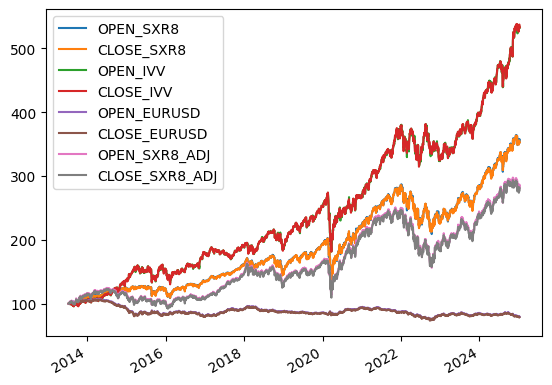

In [49]:
x.plot()
plt.legend()Bp

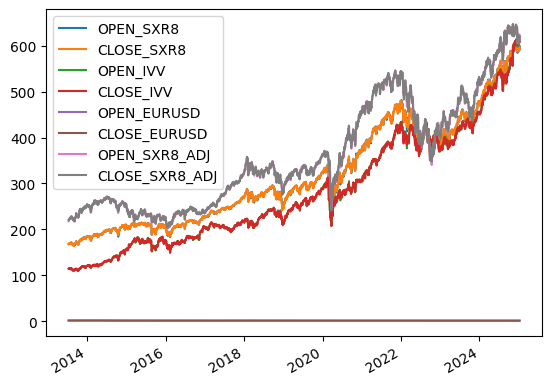

In [50]:
data.plot()
plt.legend()

In [51]:
r = np.log((data / data.shift(1)).dropna())

In [52]:
r

,OPEN_SXR8,CLOSE_SXR8,OPEN_IVV,CLOSE_IVV,OPEN_EURUSD,CLOSE_EURUSD,OPEN_SXR8_ADJ,CLOSE_SXR8_ADJ
2013-07-12,0.001903,-0.000356,0.000525,0.002012,0.009052,-0.002141,0.010955,-0.002497
2013-07-15,0.003263,0.004444,0.003581,0.005577,-0.002294,-0.000306,0.000969,0.004138
2013-07-16,0.001834,-0.004206,-0.00061,-0.012065,-0.000306,0.007551,0.001528,0.003344
2013-07-17,-0.000532,0.002135,-0.006476,0.006488,0.007551,-0.002815,0.007019,-0.00068
2013-07-18,0.00071,0.005671,0.012304,0.008788,-0.002739,-0.001144,-0.00203,0.004527
...,...,...,...,...,...,...,...,...
2025-01-02,0.00235,-0.005991,-0.00033,0.016475,-0.007602,-0.013739,-0.005252,-0.01973
2025-01-03,-0.003095,0.012115,0.002309,-0.000557,-0.008537,0.00418,-0.011632,0.016295
2025-01-06,0.014813,0.006187,0.006502,0.005326,0.003598,0.007924,0.018412,0.01411
2025-01-07,0.001901,-0.011312,-0.00456,-0.010023,0.008603,-0.004921,0.010504,-0.016233


In [53]:
spread_prices = data.loc[:,'CLOSE_IVV'] - data.loc[:,'CLOSE_SXR8']
spread_prices_adj = data.loc[:,'CLOSE_IVV'] - data.loc[:,'CLOSE_SXR8_ADJ']

spread_returns = r.loc[:,'CLOSE_IVV'] - r.loc[:,'CLOSE_SXR8']

<Axes: >

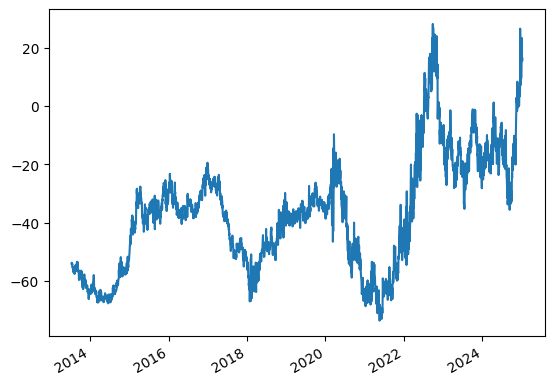

In [54]:
spread_prices.plot()

<Axes: >

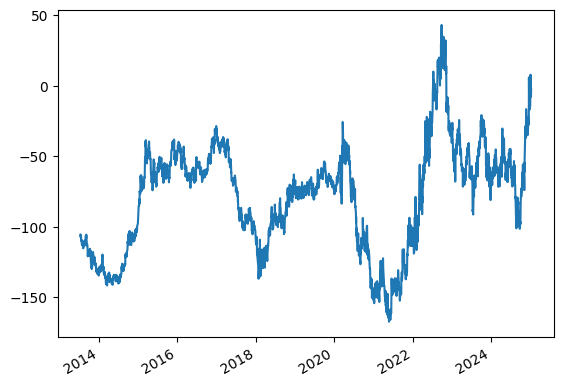

In [55]:
spread_prices_adj.plot()

In [56]:
# correlation order 1 between (USD_t, EUR_t+1)
print(np.corrcoef(r.loc[:,'CLOSE_IVV'].iloc[:-1], r.loc[:,'OPEN_SXR8'].iloc[1:]))
# autocorrelation order 1 between (USD_t, USD_t+1)
print(np.corrcoef(r.loc[:,'CLOSE_IVV'].iloc[:-1], r.loc[:,'CLOSE_IVV'].iloc[1:]))
# autocorrelation order 1 between (EUR_t, EUR_t+1)
print(np.corrcoef(r.loc[:,'CLOSE_SXR8'].iloc[:-1], r.loc[:,'CLOSE_SXR8'].iloc[1:]))

[[1.         0.16164163]
 [0.16164163 1.        ]]
[[ 1.         -0.03655423]
 [-0.03655423  1.        ]]
[[ 1.         -0.12741889]
 [-0.12741889  1.        ]]


In [57]:
data = data.join(r, how='left', rsuffix='_ret')
data.dropna(inplace=True)


In [58]:
data.loc[:, 'signal'] = (data.loc[:, 'CLOSE_IVV_ret'] < 0).astype(int)
data

,OPEN_SXR8,CLOSE_SXR8,OPEN_IVV,CLOSE_IVV,OPEN_EURUSD,CLOSE_EURUSD,OPEN_SXR8_ADJ,CLOSE_SXR8_ADJ,OPEN_SXR8_ret,CLOSE_SXR8_ret,OPEN_IVV_ret,CLOSE_IVV_ret,OPEN_EURUSD_ret,CLOSE_EURUSD_ret,OPEN_SXR8_ADJ_ret,CLOSE_SXR8_ADJ_ret,signal
2013-07-12,168.069597,168.16946,114.29,114.43,1.3095,1.3066,220.087138,219.730217,0.001903,-0.000356,0.000525,0.002012,0.009052,-0.002141,0.010955,-0.002497,0
2013-07-15,168.618844,168.918434,114.7,115.07,1.3065,1.3062,220.30052,220.641258,0.003263,0.004444,0.003581,0.005577,-0.002294,-0.000306,0.000969,0.004138,0
2013-07-16,168.92842,168.209406,114.63,113.69,1.3061,1.3161,220.637409,221.380399,0.001834,-0.004206,-0.00061,-0.012065,-0.000306,0.007551,0.001528,0.003344,1
2013-07-17,168.838543,168.568913,113.89,114.43,1.316,1.3124,222.191523,221.229841,-0.000532,0.002135,-0.006476,0.006488,0.007551,-0.002815,0.007019,-0.00068,0
2013-07-18,168.958379,169.527599,115.3,115.44,1.3124,1.3109,221.740976,222.233729,0.00071,0.005671,0.012304,0.008788,-0.002739,-0.001144,-0.00203,0.004527,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-01-02,592.17,587.45,605.68,610.76,1.0352,1.0265,613.014384,603.017425,0.00235,-0.005991,-0.00033,0.016475,-0.007602,-0.013739,-0.005252,-0.01973,0
2025-01-03,590.34,594.61,607.08,610.42,1.0264,1.0308,605.924976,612.923988,-0.003095,0.012115,0.002309,-0.000557,-0.008537,0.00418,-0.011632,0.016295,1
2025-01-06,599.15,598.3,611.04,613.68,1.0301,1.039,617.184415,621.6337,0.014813,0.006187,0.006502,0.005326,0.003598,0.007924,0.018412,0.01411,0
2025-01-07,600.29,591.57,608.26,607.56,1.039,1.0339,623.70131,611.624223,0.001901,-0.011312,-0.00456,-0.010023,0.008603,-0.004921,0.010504,-0.016233,1


In [67]:
am = arch_model(100 * data['CLOSE_IVV_ret'] ** 2, vol="Garch", p=1, o=0, q=1, dist="Normal")
res = am.fit(update_freq=1)
res

Iteration:      1,   Func. Count:      6,   Neg. LLF: 94376136951.75438
Iteration:      2,   Func. Count:     20,   Neg. LLF: 15770698169819.422
Iteration:      3,   Func. Count:     35,   Neg. LLF: 10402239630.70303
Iteration:      4,   Func. Count:     48,   Neg. LLF: 10760665.545807855
Iteration:      5,   Func. Count:     59,   Neg. LLF: -7309.662715885059
Optimization terminated successfully    (Exit mode 0)
            Current function value: -7309.662740451697
            Iterations: 9
            Function evaluations: 59
            Gradient evaluations: 5


                     Constant Mean - GARCH Model Results                      
Dep. Variable:          CLOSE_IVV_ret   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                7309.66
Distribution:                  Normal   AIC:                          -14611.3
Method:            Maximum Likelihood   BIC:                          -14587.5
                                        No. Observations:                 2840
Date:                Sun, Feb 23 2025   Df Residuals:                     2839
Time:                        22:33:05   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu         6.1536e-03  5.941e-04     10.358  3.849e-25 [4.

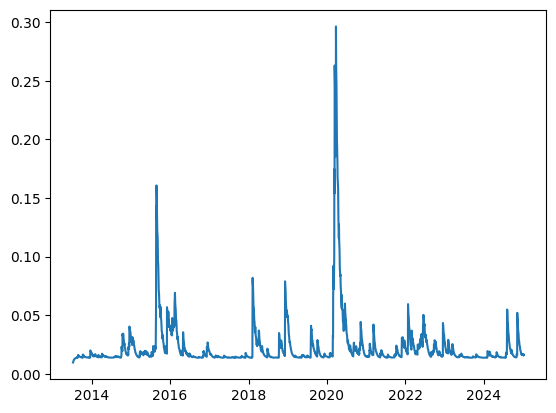

In [68]:
plt.plot(res.conditional_volatility)

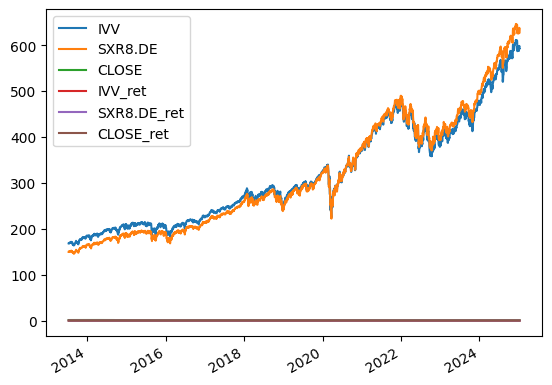

In [28]:
data.plot()
plt.legend()

In [29]:
avg_buy_price = data.iloc[np.arange(0,len(x), 31),:].mean()
last_price = data.iloc[-1,:]

In [30]:
avg_buy_price

IVV            315.836609
SXR8.DE         313.99477
CLOSE            1.148154
IVV_ret         -0.000998
SXR8.DE_ret     -0.001029
CLOSE_ret       -0.000385
signal           0.526882
dtype: Float64

In [31]:
last_price

IVV                592.19
SXR8.DE        627.726484
CLOSE              1.0318
IVV_ret          0.001048
SXR8.DE_ret     -0.000684
CLOSE_ret       -0.002033
signal              False
Name: 2025-01-08 00:00:00, dtype: object

In [32]:
(last_price - avg_buy_price) / avg_buy_price

IVV            0.874988
SXR8.DE        0.999162
CLOSE          -0.10134
IVV_ret       -2.049336
SXR8.DE_ret   -0.335106
CLOSE_ret      4.277834
signal             -1.0
dtype: object

In [4]:
import okx.MarketData as MarketData

flag = "0"  # Production trading:0 , demo trading:1

marketDataAPI =  MarketData.MarketAPI(flag=flag)

# Retrieve history candlestick charts from recent years
result = marketDataAPI.get_history_candlesticks(
    instId="SOL-USDT"
)
print(result)


{'code': '0', 'msg': '', 'data': [['1740268920000', '172.23', '172.23', '172.15', '172.16', '10.430164', '1796.06118487', '1796.06118487', '1'], ['1740268860000', '172.07', '172.27', '172.07', '172.24', '170.754408', '29406.36382919', '29406.36382919', '1'], ['1740268800000', '172.08', '172.14', '171.95', '172.06', '743.830629', '127945.54936578', '127945.54936578', '1'], ['1740268740000', '172.11', '172.11', '172.05', '172.08', '132.822252', '22856.44977364', '22856.44977364', '1'], ['1740268680000', '172.13', '172.13', '172.11', '172.11', '14.226587', '2448.5452526', '2448.5452526', '1'], ['1740268620000', '172.13', '172.14', '172.11', '172.14', '27.711209', '4769.60467798', '4769.60467798', '1'], ['1740268560000', '172.1', '172.14', '172.1', '172.12', '20.654684', '3554.94417872', '3554.94417872', '1'], ['1740268500000', '172.2', '172.2', '172.1', '172.1', '59.144446', '10180.1310323', '10180.1310323', '1'], ['1740268440000', '172.15', '172.22', '172.12', '172.22', '15.460667', '266

In [9]:
result.keys()

dict_keys(['code', 'msg', 'data'])

In [13]:
len(solusdt_okx)

100

In [12]:
solusdt_okx = pd.DataFrame(result['data'])
solusdt_okx

,0,1,2,3,4,5,6,7,8
0,1740268920000,172.23,172.23,172.15,172.16,10.430164,1796.06118487,1796.06118487,1
1,1740268860000,172.07,172.27,172.07,172.24,170.754408,29406.36382919,29406.36382919,1
2,1740268800000,172.08,172.14,171.95,172.06,743.830629,127945.54936578,127945.54936578,1
3,1740268740000,172.11,172.11,172.05,172.08,132.822252,22856.44977364,22856.44977364,1
4,1740268680000,172.13,172.13,172.11,172.11,14.226587,2448.5452526,2448.5452526,1
...,...,...,...,...,...,...,...,...,...
95,1740263220000,173.18,173.24,173.17,173.17,120.857761,20931.29742122,20931.29742122,1
96,1740263160000,173.16,173.2,173.16,173.19,38.032678,6586.61403588,6586.61403588,1
97,1740263100000,173.11,173.16,173.05,173.16,951.977988,164806.25957328,164806.25957328,1
98,1740263040000,173.17,173.17,173.12,173.12,57.406173,9939.46666803,9939.46666803,1


In [17]:
solusdt_okx.columns

RangeIndex(start=0, stop=9, step=1)

In [18]:
solusdt_binance = pd.read_csv(r'C:\Users\serge\Downloads\SOLUSDT-aggTrades-2025-02-19\SOLUSDT-aggTrades-2025-02-19.csv')
solusdt_binance.columns = range(len(solusdt_binance.columns))

In [19]:
solusdt_binance

,0,1,2,3,4,5,6,7
0,502092334,169.32,0.454,1081724404,1081724414,1739923200286525,False,True
1,502092335,169.33,1.201,1081724415,1081724418,1739923200286525,False,True
2,502092336,169.32,1.139,1081724419,1081724419,1739923200498910,True,True
3,502092337,169.32,0.890,1081724420,1081724420,1739923200605383,True,True
4,502092338,169.32,0.053,1081724421,1081724421,1739923200629090,True,True
...,...,...,...,...,...,...,...,...
400774,502493108,168.93,4.901,1083909472,1083909483,1740009596955326,True,True
400775,502493109,168.93,0.060,1083909484,1083909485,1740009596957321,True,True
400776,502493110,168.92,0.148,1083909486,1083909488,1740009597355511,True,True
400777,502493111,168.93,0.376,1083909489,1083909500,1740009598980466,False,True


<Axes: >

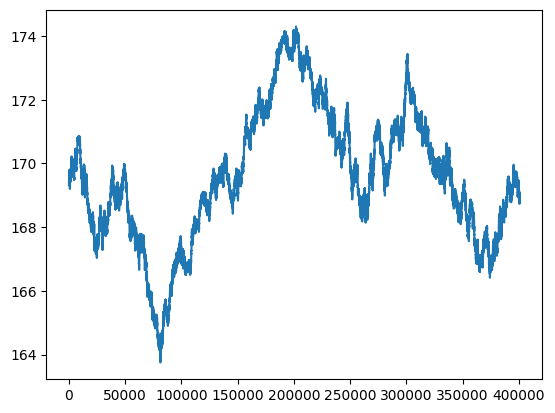

In [24]:
solusdt_binance.iloc[:,1].plot()

<Axes: >

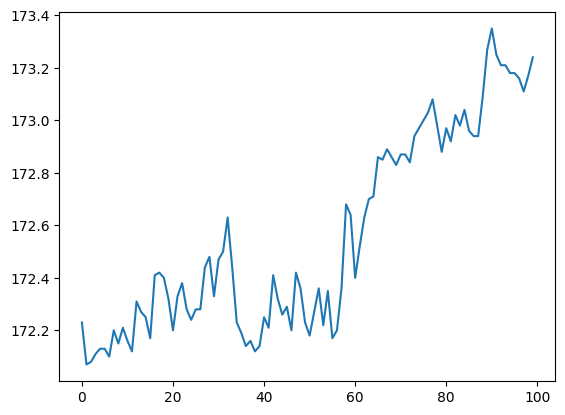

In [31]:
solusdt_okx.iloc[:,1].astype(float).plot()